# Clients for other web services

The service classes cover NWIS, FabricData, and GeoConnex. The transport under them,
the async `Transport` and its blocking `Client`, sends requests to any HTTP API: it
bounds how many run at once, retries transient failures, refuses redirects outside
downloads, and keeps credentials out of logs and errors. This notebook builds small
clients for three other USGS services, the way a package such as HyRiver builds on
water-ogcapi, and uses them on one basin, Difficult Run near Great Falls, Virginia:

- the NLDI, a REST API that returns GeoJSON;
- 3DHP hydrography, an ArcGIS FeatureServer;
- 3DEP elevation, an ArcGIS ImageServer that returns a GeoTIFF.

One `Transport` serves all three, so they share its connections and its concurrency
bound. `user_agent` names the calling package in every request.

In [1]:
import asyncio

from water_ogcapi import Client, Transport

transport = Transport(user_agent="water-ogcapi-example/0.1")
client = Client(transport=transport)

## NLDI: REST requests that return JSON

`Client.get()` sends one request and returns a `Response`. Query values can be strings,
numbers, or booleans; a `bool` goes out as `true` or `false`.

In [2]:
NLDI = "https://api.water.usgs.gov/nldi/linked-data"
SITE = "USGS-01646000"

site = client.get(f"{NLDI}/nwissite/{SITE}").json()["features"][0]
print(site["properties"]["name"], "on COMID", site["properties"]["comid"])
basin = client.get(f"{NLDI}/nwissite/{SITE}/basin", params={"simplified": True}).json()
upstream = client.get(
    f"{NLDI}/nwissite/{SITE}/navigation/UT/flowlines", params={"distance": 100}
).json()
print(len(upstream["features"]), "NHDPlus flowlines upstream of the gage")

DIFFICULT RUN NEAR GREAT FALLS, VA on COMID 4509202


95 NHDPlus flowlines upstream of the gage


A client is a class whose async methods send through one transport. Its blocking twin
passes each coroutine to `Client.run()`, which runs it on the background loop every
blocking call shares, so one blocking call can send many requests at once. `features()`
fetches several NLDI features concurrently; with `return_exceptions=True` a feature that
fails comes back as its `ServiceError`, in its place, and the others still arrive. The
error carries the status and the server's own error body.

In [3]:
from typing import Any

from water_ogcapi.exceptions import ServiceError


class AsyncNLDI:
    def __init__(self, transport: Transport) -> None:
        self.transport = transport

    async def feature(self, path: str) -> dict[str, Any]:
        response = await self.transport.get(f"{NLDI}/{path}")
        return response.json()["features"][0]

    async def features(self, paths: list[str]) -> list[dict[str, Any] | BaseException]:
        return await asyncio.gather(*map(self.feature, paths), return_exceptions=True)


class NLDIClient:
    def __init__(self, client: Client) -> None:
        self._client = client
        self._aio = AsyncNLDI(client.transport)

    def features(self, paths: list[str]) -> list[dict[str, Any] | BaseException]:
        return self._client.run(self._aio.features(paths))


nldi = NLDIClient(client)
paths = [f"nwissite/{SITE}", "nwissite/USGS-01645704", "nwissite/USGS-01654000", "comid/999999999"]
for path, found in zip(paths, nldi.features(paths), strict=True):
    if isinstance(found, ServiceError):
        print(f"{path}: HTTP {found.status}, {(found.response_body or b'').decode()}")
    else:
        print(f"{path}: {found['properties']['name']}")

nwissite/USGS-01646000: DIFFICULT RUN NEAR GREAT FALLS, VA
nwissite/USGS-01645704: DIFFICULT RUN ABOVE FOX LAKE NEAR FAIRFAX, VA
nwissite/USGS-01654000: ACCOTINK CREEK NEAR ANNANDALE, VA
comid/999999999: HTTP 404, {"type":"about:blank","title":"Not Found","status":404,"detail":"COMID 999999999 not found."}


## 3DHP: an ArcGIS FeatureServer

An ArcGIS query takes two steps: one request for the object ids inside a box, then the
features in chunks of ids. Each request is a form `POST`, sent with `content=` and its
`Content-Type`, and the chunks run concurrently, `max_concurrent` at a time (4 by
default). Two ArcGIS habits shape the client:

- Most failures come back as `{"error": ...}` with HTTP 200, so the client reads the body.
- A response over the server's size limit can fail with HTTP 500 on every try, so each chunk
  goes out with `max_retries=0` and a 500 halves it; other requests keep the
  transport's retries.

In [4]:
from urllib.parse import urlencode

FORM = {"Content-Type": "application/x-www-form-urlencoded"}


class ArcGISLayer:
    def __init__(self, url: str, transport: Transport, *, chunk: int = 500) -> None:
        self.url, self.transport, self.chunk = url, transport, chunk

    async def _query(self, form: dict[str, Any], **kwargs: Any) -> dict[str, Any]:
        response = await self.transport.request(
            "POST", f"{self.url}/query", content=urlencode(form).encode(), headers=FORM, **kwargs
        )
        data = response.json()
        if "error" in data:
            raise ServiceError(str(data["error"]), response.url, status=response.status)
        return data

    async def _chunk(self, ids: list[int]) -> list[dict[str, Any]]:
        form = {"objectIds": ",".join(map(str, ids)), "outFields": "*", "f": "geojson"}
        try:
            page = await self._query(form | {"outSR": 4326}, max_retries=0)
        except ServiceError as err:
            if err.status != 500 or len(ids) == 1:
                raise
            half = len(ids) // 2
            first, second = await asyncio.gather(self._chunk(ids[:half]), self._chunk(ids[half:]))
            return first + second
        return page["features"]

    async def bygeom(self, bbox: tuple[float, float, float, float]) -> dict[str, Any]:
        query = {"geometry": ",".join(map(str, bbox)), "geometryType": "esriGeometryEnvelope"}
        query |= {"inSR": 4326, "spatialRel": "esriSpatialRelIntersects"}
        found = await self._query(query | {"returnIdsOnly": "true", "f": "json"})
        ids = sorted(found["objectIds"] or [])
        chunks = [ids[i : i + self.chunk] for i in range(0, len(ids), self.chunk)]
        pages = await asyncio.gather(*map(self._chunk, chunks))
        features = [feature for page in pages for feature in page]
        # A server can leave records out of a chunk without an error.
        if sorted(feature["id"] for feature in features) != ids:
            msg = "features missing from the response"
            raise ServiceError(msg, self.url)
        return {"type": "FeatureCollection", "features": features}

In [5]:
import geopandas as gpd

HP3D = "https://3dhp.nationalmap.gov/arcgis/rest/services/usgs_3dhp_all/FeatureServer/50"

outline = gpd.GeoDataFrame.from_features(basin["features"], crs=4326)
flowlines = ArcGISLayer(HP3D, transport)
fc = client.run(flowlines.bygeom(tuple(outline.total_bounds)))
hp3d = gpd.GeoDataFrame.from_features(fc["features"], crs=4326).clip(outline)
print(len(fc["features"]), "3DHP flowlines in the box,", len(hp3d), "inside the basin")

1019 3DHP flowlines in the box, 280 inside the basin


## 3DEP: a GeoTIFF from an ImageServer

`Client.download()` streams a response to a file. The body goes to a temporary `.part`
file, renamed into place once complete, and the result reports the status, size, and
attempts. A download also follows redirects, keeping only a few headers once one leaves
the first origin, as files behind signed storage URLs need. Here `exportImage` returns
the basin's elevation in EPSG:5070, an equal-area projection of the contiguous United
States.

In [6]:
import tempfile
from pathlib import Path

DEM = "https://elevation.nationalmap.gov/arcgis/rest/services/3DEPElevation/ImageServer"

box = outline.to_crs(5070).total_bounds
params = {
    "bbox": ",".join(f"{v:.0f}" for v in box),
    "bboxSR": 5070,
    "imageSR": 5070,
    "size": "600,600",
    "format": "tiff",
    "pixelType": "F32",
    "f": "image",
}
folder = Path(tempfile.mkdtemp())
dem = client.download(f"{DEM}/exportImage", folder / "dem.tif", params=params)
print(dem.status, f"{dem.size / 1e6:.1f} MB", dem.headers.get("content-type"))

200 1.6 MB image/tiff


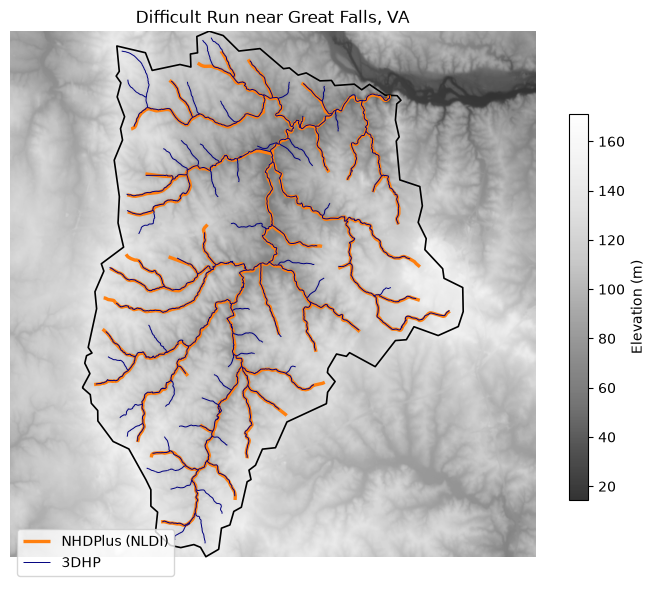

In [7]:
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show

with rasterio.open(dem.path) as src:
    fig, ax = plt.subplots(figsize=(7, 6))
    image = show(src, ax=ax, cmap="Greys_r", alpha=0.8)
    nhdplus = gpd.GeoDataFrame.from_features(upstream["features"], crs=4326).clip(outline)
    outline.to_crs(src.crs).boundary.plot(ax=ax, color="black", linewidth=1.2)
    nhdplus.to_crs(src.crs).plot(ax=ax, color="tab:orange", linewidth=2.4, label="NHDPlus (NLDI)")
    hp3d.to_crs(src.crs).plot(ax=ax, color="navy", linewidth=0.7, label="3DHP")
fig.colorbar(image.get_images()[0], ax=ax, shrink=0.7, label="Elevation (m)")
ax.legend(loc="lower left")
ax.set(title="Difficult Run near Great Falls, VA")
ax.set_axis_off()
plt.tight_layout()

The orange lines are the NHDPlus flowlines the NLDI navigates; the navy ones are 3DHP's
elevation-derived hydrography, which reaches the smaller headwater channels.

In [8]:
client.close()